In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload() # Opens a dialog to select and upload files

Saving South Dakota State_0466.csv to South Dakota State_0466.csv


### Data Overview
## pitch_cols =
* **RelSpeed**: Indicates the initial speed of a pitch. Presented in Miles per Hour (mph).
    * DI Pitch Velocity Avg:
    * Fastball 61 mph
    * Dropball 60 mph
    * Riseball 59 mph
    * Curveball 60 mph
    * Screwball 59 mph
    * Changeup 48 mph
* **SpinRate**: Indicates the rate at which the softball is spinning as it leaves the pitcher’s hand.
Presented in Revolutions per Minute (rpm).
    * DI Pitch Spin Avg:
    * Fastball 1000- 1100 rpm
    * Dropball 1000- 1100 rpm
    * Riseball 1300- 1400 rpm
    * Curveball 1200-1300 rpm
    * Screwball 1100- 1200 rpm
    * Changeup 900- 1000 rpm
* **VertRelAngle**: Initial vertical (up-down) direction of the ball when it leaves the
pitcher’s hand. Presented in degrees.
  * Positive numbers indicate the ball was released
upward.
  * Negative numbers indicate the ball was released downward.
* **HorzRelAngle**: Initial horizontal (left-right) direction of the ball when it leaves the
pitcher’s hand. Presented in degrees.
  * From a pitcher's perspective, positive numbers indicate the ball was released to the right.
  * From a pitcher’s perspective, negative numbers indicate the ball was released to the left
* **SpinAxis**: indicates the direction at which the softball is spinning once it's
released by the pitcher. Presented in degrees.
* **Tilt**: Indicates spin axis reformed into clock time.
* **RelHeight**: The height of the pitcher's release points from the ground. Presented in Feet.
* **RelSide**: Indicates the distance from the center of the rubber at which the pitcher releases
the softball.
  * From a pitcher’s perspective, positive numbers indicate the ball was released from the
right side.
  * From a pitcher’s perspective, negative numbers indicate the ball was released from the
left side.
* **Extension**: Indicates the distance from which the pitcher releases the softball relative to the
pitching rubber. Presented in Feet.
* **InducedVertBreak**: Vertical pitch movement determined at a full distance reported
without the effect of gravity. Represents where the pitch actually crossed home plate
(height wise) and where it would have crossed if the same pitch was thrown in a straight
line from release, affected by gravity and drag. Presented in inches. *Positive numbers do
not indicate the ball rose.
* **HorzBreak**: Horizontal pitch movement, determined at full distance, reported with the
effect of gravity from the pitcher’s perspective. Indicates the horizontal distance between
where the softball crosses home plate and where it would have crossed if the pitch was
thrown in a straight line without any break.
  * Positive numbers indicate the softball was to the right from a pitcher's
perspective.
  * Negative numbers indicate the softball was to the left from the pitcher’s
perspective.
* **VertBreak**: Vertical pitch movement determined at full distance. Presented in Inches.
* **PlateLocHeight**: The height of the ball relative to home plate as the ball
crosses the front of the plate. Presented in Inches.
* **PlateLocSide**: The distance between the center home plate to the ball as it
crosses the front of the plate. Presented in Inches.
  * From a pitcher’s perspective, positive numbers indicate the ball crossed the right side
of the plate [inside to right handed hitter].
  * From a pitcher’s perspective, negative numbers indicate the ball crossed the left side
of the plate [inside to a left handed hitter].
* **ZoneSpeed**: Speed of the pitch as it crosses the front of home plate. (miles/hr).
* **VertApprAngle**: How steeply up or down the ball enters the zone, reported as the angle in degrees, as the pitch crosses the front of home plate.
  * A negative number means it is sloping downward.
  * A positive number means it is sloping upward.
* **HorzApprAngle**: Left-right direction at which a pitched ball crosses the front of home plate, reported as an angle.
  * A negative number indicates that the ball is
moving from right to left from the pitcher’s perspective as it enters the zone.
  * A positive number means that the ball is moving from left to right from the pitcher’s perspective as it enters the zone.
* **ZoneTime**: The time it takes for the ball to travel from release to the front of home plate. (seconds).
* **pfxx**: The horizontal movement from the catcher’s perspective, determined at the last 40
feet.
  * This parameter is measured at y=40 feet regardless of the y0 value. (inches).
* **pfxz**: The vertical movement from the catcher’s perspective, determined at the last 40
feet.
  * This parameter is measured at y=40 feet regardless of the y0 value. (inches).
* **x0**: the left/ right distance of the pitch, determined at 50 feet. (feet).
  * From a catcher’s perspective, negative numbers are to the left.
  * From a catcher’s perspective, positive numbers are to the right.
* **y0**: The distance from home plate where the X3B is set to measure the initial parameters (feet).
* **z0**: The height of the pitch presented at the initial point (feet).
* **vx0**: the velocity of the pitch, at the initial point (ft/s)
* **vy0**: the velocity of the pitch, at the initial point (ft/s)
* **vz0**: the velocity of the pitch, at the initial point (ft/s)
* **ax**: the acceleration of the pitch, at the initial point (ft/s)
* **ay**: the acceleration of the pitch, at the initial point (ft/s)
* **az**: the acceleration of the pitch, at the initial point (ft/s)
* **PositionAt110X**: Horizontal position of the ball when it crosses the front of home plate from the catcher’s perspective (inches).
* **PositionAt110Y**: Vertical position of the ball when it crosses the front of home plate from the catcher’s perspective (inches).
* **PositionAt110Z**: z position of the ball when it crosses the front of home plate from the catcher’s perspective (inches).


## hit_cols =
* **ExitSpeed**: Speed of the softball as it leaves the bat. Presented in Miles Per Hour
(mph).
* **Angle**: Indicates the vertical angle at which the softball leaves the bat after the
batter has made contact. Presented in degrees.
  * Dribbler: <0 degrees
  * Ground Ball: 0-6 degrees
  * Low Line Drive: 6-15 degrees
  * High Line Drive: 15-25 degrees
  * Fly Ball: 25-50 degrees
  * Pop Up: >50 degrees
* **Direction**: Indicates the horizontal angle at which the softball leaves the bat after
the batter has made contact. Presented in degrees.
Straight line from the tip of home plate to the middle of the outfield wall is 0 degrees.
  * Right field foul pole is 45 degrees right (positive).
  * Left field foul pole is 45 degrees left (negative).
* **Distance**: The total carry distance of the softball after the batter has made contact with
the softball in fair play. Presented in Feet (ft).
* **HangTime**: Indicates the amount of time the softball was in flight from the point of
contact to landing. Presented in Seconds.
* **HitSpinRate**: ft/sec?

In [3]:
df = pd.read_csv('South Dakota State_0466.csv')

In [4]:
def print_shape(df):
  print(f"Cols: {df.shape[1]}")
  print(f"Rows: {df.shape[0]}")

def print_unique(df, col):
  print(f"{col}: {df[col].unique()}")
  print(df[col].value_counts(dropna=False))

def print_missing(df, cols_per_row=2, pct=True):
    if pct:
      missing = (df.isna().mean().mul(100).round(1).sort_values(ascending=False)    )
      items = [f"{col}: {val}%" for col, val in missing.items()]
    else:
      missing = (df.isna().sum().sort_values(ascending=False))
      items = [f"{col}: {val}" for col, val in missing.items()]

    for i in range(0, len(items), cols_per_row):
        print(" | ".join(f"{x:<30}" for x in items[i:i+cols_per_row]))

In [5]:
pitch_cols = [
'RelSpeed', 'SpinRate',
'VertRelAngle', 'HorzRelAngle',
'SpinAxis', 'Tilt',
'RelHeight', 'RelSide',
'Extension',
'InducedVertBreak', 'HorzBreak', 'VertBreak',
'PlateLocHeight', 'PlateLocSide',
'ZoneSpeed', 'VertApprAngle', 'HorzApprAngle',
'ZoneTime',
'pfxx', 'pfxz',
'x0', 'y0', 'z0',
'vx0', 'vy0', 'vz0',
'ax0', 'ay0', 'az0',
#'PositionAt110X', 'PositionAt110Z', 'PositionAt110Z'
]

hit_cols = [
'ExitSpeed', 'Angle', 'Direction',
'Distance', 'HangTime', 'HitSpinRate'
]

name_cols = [
    'HomeTeam', 'AwayTeam',
    'Pitcher', 'PitcherTeam', 'TaggedPitchType', 'PitchCall', 'PlayResult',
    'Batter', 'BatterTeam', 'BatterSide', 'HitType',
    'Catcher', 'CatcherTeam',
]

### Note for yt columns: 'yt' most likely is going to be noise because it mirrors the other data.

In [6]:
print_shape(df,)

Cols: 125
Rows: 259


In [7]:
# note, it is better (and easier) to create a new dataframe from a mask than to drop cols.

# drop 100% missing columns
df.dropna(axis='columns', how='all', inplace=True)
# drop missing rows > 80
df = df.loc[:, df.isnull().mean() < 0.80]
# dropped all 'yt_' columns
df = df.filter(regex='^(?!yt_)')
# dropped these columns that make no sense, yet!
df.drop(columns=['PitchNo',
                 'PitchUUID',
                 'BatterId',
                 'PitcherId',
                 'CatcherId',
                 'Date','Time'
                 ], inplace=True)

# Typos!
df.replace('RIse', 'Rise', inplace=True)

# Converting Tilt from time to degrees
time_parts = pd.to_datetime(df['Tilt'], format='%H:%M')
df['Tilt'] = (time_parts.dt.hour * 30 + time_parts.dt.minute * 0.5) % 360
df.reset_index(inplace=True)

In [8]:
print_missing(df,)

OutsOnPlay: 76.1%              | RunsScored: 76.1%             
PlayResult: 76.1%              | TaggedPitchType: 51.0%        
az0: 8.9%                      | pfxx: 8.9%                    
pfxz: 8.9%                     | x0: 8.9%                      
y0: 8.9%                       | z0: 8.9%                      
vx0: 8.9%                      | vy0: 8.9%                     
vz0: 8.9%                      | ax0: 8.9%                     
InducedVertBreak: 8.9%         | ZoneTime: 8.9%                
HorzBreak: 8.9%                | VertBreak: 8.9%               
Tilt: 8.9%                     | SpinAxis: 8.9%                
SpinRate: 8.9%                 | ay0: 8.9%                     
VertRelAngle: 7.7%             | HorzApprAngle: 7.7%           
PlateLocSide: 7.7%             | PlateLocHeight: 7.7%          
RelHeight: 7.7%                | RelSide: 7.7%                 
Extension: 7.7%                | HorzRelAngle: 7.7%            
VertApprAngle: 7.7%            | ZoneSpe

In [9]:
print_shape(df)

Cols: 53
Rows: 259


/tmp/ipykernel_451/3059018596.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
/tmp/ipykernel_451/3059018596.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)


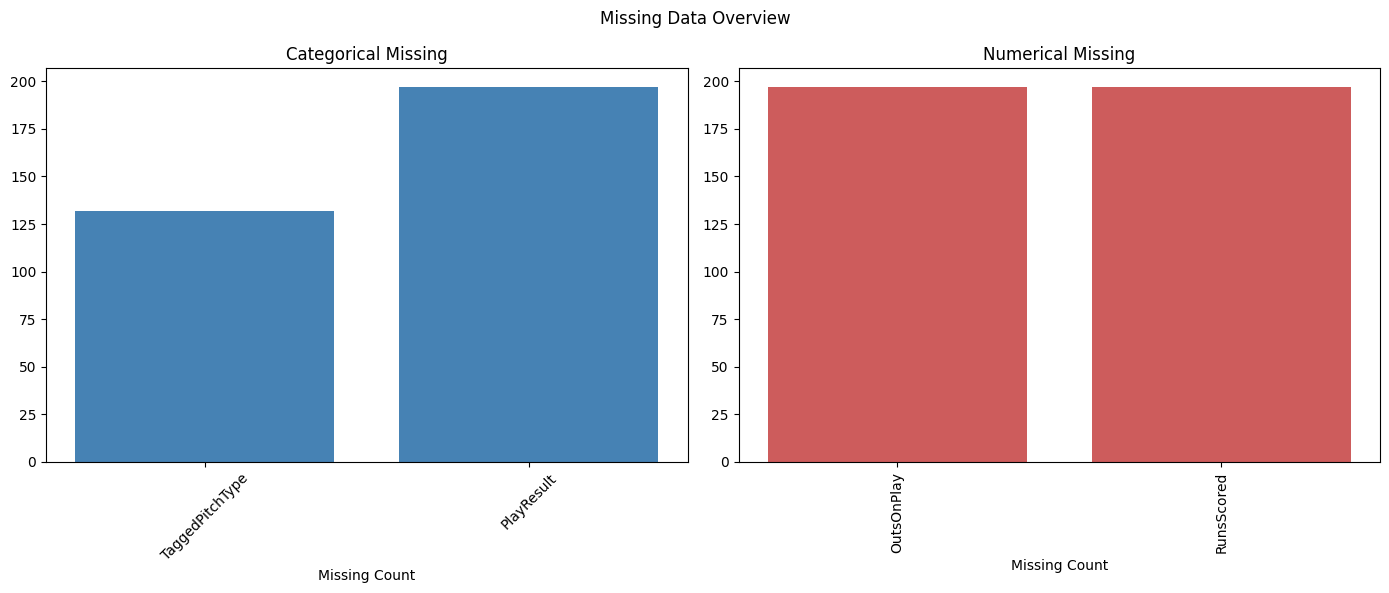

In [10]:
def plot_missing(df):
  # Split columns by dtype
  cat_cols = df.select_dtypes(include=['object', 'category']).columns
  num_cols = df.select_dtypes(include=['number']).columns

  # Missing counts
  missing_cat = df[cat_cols].isna().sum().sort_values()
  missing_num = df[num_cols].isna().sum().sort_values()

  # Plot
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

  # Categorical
  ax1.bar(missing_cat[missing_cat > 1].index, missing_cat[missing_cat > 1].values, color='steelblue')
  ax1.set_title("Categorical Missing")
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
  ax1.set_xlabel("Missing Count")

  # Numerical
  ax2.bar(missing_num[missing_num > 25].index, missing_num[missing_num > 25].values, color='indianred')
  ax2.set_title("Numerical Missing")
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)
  ax2.set_xlabel("Missing Count")

  fig.suptitle("Missing Data Overview")
  plt.tight_layout()
  plt.show()
plot_missing(df)

### We are going to focus on Pitches in this notebook.

## This stage is about imputation of the categorical variable, 'TaggedPitchType'.

### Using:
  * KNN
  * KMeans

* Both types of clustering is used to impute the column, and the results are confident. This could translate well to the 'HitType' column only if 'Angle' weren't >80% missing.

### Why do we need to impute 'TaggedPitchType'?:
  * We need to be able to classify the type of pitch thrown, and because the rest of the categorical variables are not missing.
  * We can plot differences easily with the type of pitch known.


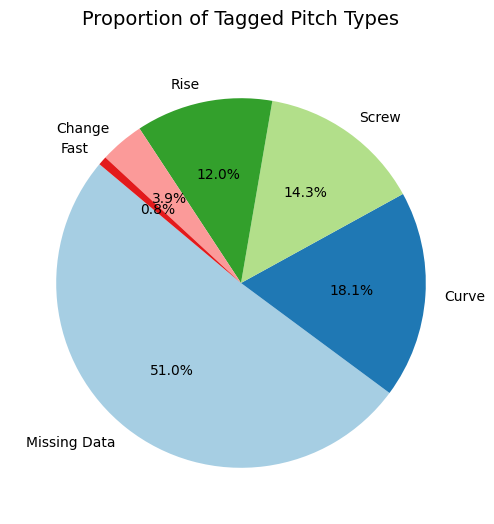

In [11]:
# 1. Calculate the proportions
pitch_data = df['TaggedPitchType'].fillna('Missing Data')
proportions = pitch_data.value_counts(normalize=True)
# 2. Create the figure canvas
plt.figure(figsize=(6, 6))

# 3. Plot the pie chart
plt.pie(
    proportions,
    labels=proportions.index,
    autopct='%1.1f%%',
    startangle=140,            # Rotates the start point for a cleaner alignment
    colors=plt.cm.Paired.colors # Applies a nice, clean color palette
)

# 4. Final adjustments
plt.title("Proportion of Tagged Pitch Types", fontsize=14, pad=20)
plt.ylabel("") # Clears the default pandas vertical column name label

# 5. Save or Show (using the tip from earlier!)
plt.savefig("pitch_type_proportions_before_docs.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Imputing values based on documented ranges, so that it is consistent with docs and data
####### This one relies on two colums! RelSpeed and SpinRate
## This step is the easiest because we have the documents as a guide.
before = df['TaggedPitchType'].isna().sum()

relspeed_conditions = [

    # Fast
    (df['RelSpeed'] >= 61) &
    (df['SpinRate'] >= 1000) &
    (df['SpinRate'] <= 1100),

    # Rise
    (df['RelSpeed'] <= 59) &
    (df['SpinRate'] >= 1300) &
    (df['SpinRate'] <= 1400),

    # Curve
    (df['RelSpeed'] >= 60) &
    (df['SpinRate'] >= 1200) &
    (df['SpinRate'] <= 1300),

    # Screw
    (df['RelSpeed'] <= 59) &
    (df['SpinRate'] >= 1100) &
    (df['SpinRate'] <= 1200),

    # Change
    (df['RelSpeed'] <= 48) &
    (df['SpinRate'] >= 900) &
    (df['SpinRate'] <= 1000)
]
relspeed_choices = [
    'Fast',
    'Rise',
    'Curve',
    'Screw',
    'Change'
]
##################################
# imputation code.
# Creates a flag (UNMATCHED) to fill unknown values.
predicted_pitch = np.select(
    condlist=relspeed_conditions,
    choicelist=relspeed_choices,
    default='UNMATCHED'
)

mask = df['TaggedPitchType'].isna()

df.loc[mask, 'TaggedPitchType'] = predicted_pitch[mask]

##################################

after = df['TaggedPitchType'].isna().sum()

print(f'Filled {before - after} rows with [datasheet] ranges')
print(f'Remaining unmatched: {df.loc[mask, 'TaggedPitchType'].value_counts()}')

Filled 132 rows with [datasheet] ranges
Remaining unmatched: TaggedPitchType
UNMATCHED    98
Fast         17
Curve        17
Name: count, dtype: int64


In [13]:
print_missing(df)

OutsOnPlay: 76.1%              | RunsScored: 76.1%             
PlayResult: 76.1%              | ay0: 8.9%                     
az0: 8.9%                      | pfxx: 8.9%                    
pfxz: 8.9%                     | x0: 8.9%                      
y0: 8.9%                       | z0: 8.9%                      
vx0: 8.9%                      | vy0: 8.9%                     
vz0: 8.9%                      | ax0: 8.9%                     
InducedVertBreak: 8.9%         | ZoneTime: 8.9%                
HorzBreak: 8.9%                | VertBreak: 8.9%               
Tilt: 8.9%                     | SpinAxis: 8.9%                
SpinRate: 8.9%                 | VertRelAngle: 7.7%            
RelSpeed: 7.7%                 | HorzApprAngle: 7.7%           
PlateLocSide: 7.7%             | PlateLocHeight: 7.7%          
RelHeight: 7.7%                | RelSide: 7.7%                 
Extension: 7.7%                | HorzRelAngle: 7.7%            
VertApprAngle: 7.7%            | ZoneSpe

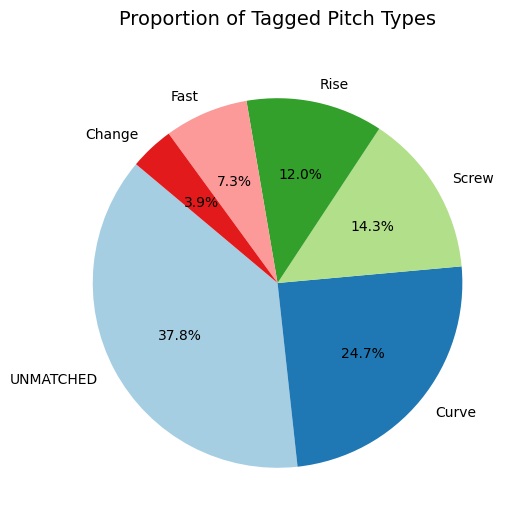

In [14]:
# 1. Calculate the proportions
proportions = df['TaggedPitchType'].value_counts(normalize=True)

# 2. Create the figure canvas
plt.figure(figsize=(6, 6))

# 3. Plot the pie chart
plt.pie(
    proportions,
    labels=proportions.index,
    autopct='%1.1f%%',
    startangle=140,            # Rotates the start point for a cleaner alignment
    colors=plt.cm.Paired.colors # Applies a nice, clean color palette
)

# 4. Final adjustments
plt.title("Proportion of Tagged Pitch Types", fontsize=14, pad=20)
plt.ylabel("") # Clears the default pandas vertical column name label

# 5. Save or Show (using the tip from earlier!)
plt.savefig("pitch_type_proportions_after_docs.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
df['TaggedPitchType'].value_counts(normalize=True).round(2)*100

,proportion
TaggedPitchType,
UNMATCHED,38.0
Curve,25.0
Screw,14.0
Rise,12.0
Fast,7.0
Change,4.0


### 11/07

##### In this stage, we use an ANN to predict the values for the 'TaggedPitchType' column.

In [16]:
import tensorflow as tf
import keras
from keras.optimizers import SGD, Adam, AdamW
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [17]:
# The scalers and encoders
scaler = StandardScaler()
one_enc = OneHotEncoder()
label_enc = LabelEncoder()

In [18]:
# Creates a copy of the dataframe for imputation model
full_df = (
    df[pitch_cols + ['TaggedPitchType']]
    .dropna(subset=['RelSpeed', 'SpinRate'])
    .copy()
)

# drop UNMATCHED
model_df = full_df[
    full_df['TaggedPitchType'] != 'UNMATCHED'
].copy()

# UNMATCHED df the ANN will predict on
unmatched_df = full_df[
    full_df['TaggedPitchType'] == 'UNMATCHED'
].copy()

In [19]:
print("unmatched rows:", len(unmatched_df))
print("contains NaN:",
      unmatched_df[pitch_cols].isna().any().any())
print("shape:",
      unmatched_df[pitch_cols].shape)

unmatched rows: 91
contains NaN: False
shape: (91, 29)


In [20]:
label_enc.fit(model_df['TaggedPitchType'])
model_df['TaggedPitchType'] = label_enc.transform(
    model_df['TaggedPitchType']
  )

num_classes = len(label_enc.classes_)


In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    model_df[pitch_cols],
    model_df['TaggedPitchType'],
    test_size=0.2,
    random_state=42,
    stratify=model_df['TaggedPitchType']
)
X_train, X_test = scaler.fit_transform(X_train), scaler.transform(X_test)
unmatched_df_scaled = scaler.transform(unmatched_df[pitch_cols])

In [22]:
class ANN:

  def __init__(self,
               X_train, X_test, y_train, y_test,
               num_classes,): # ---------------------------------------------------------------> Objects

    self.X_train, self.X_test, self.y_train, self.y_test = X_train, X_test, y_train, y_test
    self.input_dim = X_train.shape[1]
    self.num_classes = num_classes

    self.early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )#------------------------------------------------------------------------------------------------> Early Stop

    self.skf = StratifiedKFold(
        n_splits=5, shuffle=True,
        random_state=42
    )
    self.cv_scores = []
    self.histories = []

    self.weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(self.y_train),
        y=self.y_train
    )
    self.class_weights = dict(zip(np.unique(self.y_train), self.weights))
    self.optimizers = {
        "Adam": lambda: Adam(
            learning_rate=0.001
        ),

        "AdamW": lambda: AdamW(
            learning_rate=0.001,
            weight_decay=1e-4
        ),

        "SGD": lambda: SGD(
            learning_rate=0.001,
            momentum=0.9,
            nesterov=True
        )
    }

  def build_ann(self, activation=str(), optimizer=str(), dropout_rate=float()): # holds activation layers
    print(f"Activation: {activation}")

    # We use sparse categorical cross entropy because we used Label Encoding. ----------------------------> Loss Function
    loss_function = keras.losses.SparseCategoricalCrossentropy(
        from_logits=False,
        ignore_class=None,
        reduction="sum_over_batch_size",
        axis=-1,
        name="sparse_categorical_crossentropy",
        dtype=None,
    )

    # Model definition. -----------------------------------------------------------------------------> ANN Layers
    model = models.Sequential([
        layers.Input(shape=(self.input_dim,)),
        layers.BatchNormalization(),

        layers.Dense(256, activation=activation),
        layers.Dropout(dropout_rate),

        layers.Dense(128, activation=activation),
        layers.Dropout(dropout_rate),

        layers.Dense(64, activation=activation),

        layers.Dense(self.num_classes, activation='softmax')
    ])

    # compilation
    model.compile(
        optimizer=optimizer,
        loss=loss_function,
        metrics=['accuracy'],
    )

    return model

  def fit_ann(self, activation, optimizer, dropout_rate) : # epochs, batches ---------------------------------------> Training Time
    print("---Class Weights---")
    [print(f"{k}: {v:.2f}") for k,v in self.class_weights.items()]
    print()
    self.model = self.build_ann(activation, optimizer, dropout_rate)

    history = self.model.fit(
        self.X_train, self.y_train,
        epochs=100, batch_size=32,
        validation_split=0.2,
        callbacks=[self.early_stop],
        class_weight=self.class_weights,
        verbose=0
    )
    self.histories.append(history)
    return history

  def eval(self):
    print("\n--- Evaluating on Test Data ---")
    test_loss, test_acc = self.model.evaluate(self.X_test, self.y_test)
    print(f"Test Accuracy: {test_acc: .4f}")
    print(f"Test Loss: {test_loss: .4f}")
    return test_loss, test_acc

  def grid_search(self): # ----------------------------------------------------------------------> grid search!

      results = []

      activations = [
          'relu',
          'leaky_relu',
          'sigmoid',
          'tanh'
      ]

      dropout_rates = [
          0.3,
          0.4,
          0.5
      ]

      for activation in activations:

          for name, optimizer_fn in self.optimizers.items():

              for dropout_rate in dropout_rates:
                  optimizer = optimizer_fn()
                  print(
                      activation,
                      name,
                      dropout_rate
                  )

                  model = self.build_ann(
                      activation,
                      optimizer,
                      dropout_rate
                  )

                  history = model.fit(
                      self.X_train,
                      self.y_train,
                      epochs=100,
                      batch_size=32,
                      validation_split=0.2,
                      callbacks=[self.early_stop],
                      class_weight=self.class_weights,
                      verbose=0
                  )

                  test_loss, test_acc = model.evaluate(
                      self.X_test,
                      self.y_test,
                      verbose=0
                  )

                  preds = np.argmax(
                      model.predict(
                          self.X_test,
                          verbose=0
                      ),
                      axis=1
                  )

                  f1 = f1_score(
                      self.y_test,
                      preds,
                      average='weighted'
                  )

                  results.append({
                      'activation': activation,
                      'optimizer':
                          optimizer.__class__.__name__,
                      'dropout':
                          dropout_rate,
                      'f1':
                          f1,
                      'test_acc':
                          test_acc,
                      'test_loss':
                          test_loss
                  })

      results_df = pd.DataFrame(results)

      return results_df.sort_values(
          'f1',
          ascending=False
      )




  def cross_val(self, activation, optimizer, dropout_rate): # cross validation ---------------------------------------------> Cross Validation
    self.cv_scores=[]
    for fold, (train_idx, val_idx) in enumerate(self.skf.split(self.X_train, self.y_train)):
        print(f"Fold {fold+1}")
        X_train_fold, X_val_fold = self.X_train[train_idx], self.X_train[val_idx]
        y_train_fold, y_val_fold = self.y_train.iloc[train_idx], self.y_train.iloc[val_idx]

        model = self.build_ann(activation, optimizer, dropout_rate)

        history = model.fit(
            X_train_fold,
            y_train_fold,
            epochs=100,
            batch_size=32,
            validation_data=(X_val_fold, y_val_fold),
            callbacks=[self.early_stop],
            verbose=0
        )

        self.histories.append(history)

        loss,acc = model.evaluate(
            X_val_fold, y_val_fold
        )

        self.cv_scores.append(acc)

        print(f"Validation Accuracy: {acc:.4f}")
        print("-"*50)

    mean_acc = np.mean(self.cv_scores)
    print(f"Mean Acc:"
          f"{mean_acc:.4f}"
          )
    return mean_acc


  def plot_cv_loss(self): # ---------------------------------------------------------------> Plotting Cross Validation

    plt.figure(figsize=(8,5))

    for i, history in enumerate(self.histories):
        plt.plot(
            history.history['val_loss'],
            label=f'Fold {i+1}'
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation Loss")
    plt.title("Cross Validation Loss")
    plt.legend()

    plt.show()


  def plot_val(self, history): # -----------------------------------------------------------> Plotting Test Data
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train','Validation'])

    plt.subplot(1,2,2)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Train','Validation'])

    plt.tight_layout()
    plt.show()

  def diagnostic_report(self):

    preds = np.argmax(
        self.model.predict(
            self.X_test,
            verbose=0
        ),
        axis=1
    )

    print(
        classification_report(
            self.y_test,
            preds
        )
    )

    cm = confusion_matrix(
        self.y_test,
        preds
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm
    ).plot(
        xticks_rotation=45
    )

    plt.show()

In [ ]:
ann = ANN(
    X_train, X_test, y_train, y_test,
    num_classes
    )
results = ann.grid_search()

results.head(3)

relu Adam 0.3
Activation: relu
relu Adam 0.4
Activation: relu
relu Adam 0.5
Activation: relu
relu AdamW 0.3
Activation: relu
relu AdamW 0.4
Activation: relu
relu AdamW 0.5
Activation: relu
relu SGD 0.3
Activation: relu
relu SGD 0.4
Activation: relu
relu SGD 0.5
Activation: relu
leaky_relu Adam 0.3
Activation: leaky_relu
leaky_relu Adam 0.4
Activation: leaky_relu
leaky_relu Adam 0.5
Activation: leaky_relu
leaky_relu AdamW 0.3
Activation: leaky_relu
leaky_relu AdamW 0.4
Activation: leaky_relu
leaky_relu AdamW 0.5
Activation: leaky_relu
leaky_relu SGD 0.3
Activation: leaky_relu
leaky_relu SGD 0.4
Activation: leaky_relu
leaky_relu SGD 0.5
Activation: leaky_relu
sigmoid Adam 0.3
Activation: sigmoid
sigmoid Adam 0.4
Activation: sigmoid
sigmoid Adam 0.5
Activation: sigmoid
sigmoid AdamW 0.3
Activation: sigmoid
sigmoid AdamW 0.4
Activation: sigmoid
sigmoid AdamW 0.5
Activation: sigmoid
sigmoid SGD 0.3
Activation: sigmoid
sigmoid SGD 0.4
Activation: sigmoid
sigmoid SGD 0.5
Activation: sigmoid
t

,activation,optimizer,dropout,f1,test_acc,test_loss
0,relu,Adam,0.3,0.687718,0.689655,0.717602
27,tanh,Adam,0.3,0.651924,0.655172,1.134209
13,leaky_relu,AdamW,0.4,0.614822,0.620690,1.385436
32,tanh,AdamW,0.5,0.609852,0.620690,1.283519
9,leaky_relu,Adam,0.3,0.609195,0.620690,1.340503
28,tanh,Adam,0.4,0.607389,0.620690,1.159659
30,tanh,AdamW,0.3,0.606545,0.620690,1.262309
10,leaky_relu,Adam,0.4,0.570115,0.586207,1.455658
31,tanh,AdamW,0.4,0.565517,0.586207,1.181627
29,tanh,Adam,0.5,0.483117,0.517241,1.208247


In [ ]:
best = results.iloc[0]
print(best)

activation        relu
optimizer         Adam
dropout            0.3
f1            0.687718
test_acc      0.689655
test_loss     0.717602
Name: 0, dtype: object


---Training the ANN---
---Class Weights---
0: 2.90
1: 0.52
2: 1.55
3: 1.01
4: 0.93

Activation: relu

--- Evaluating on Test Data ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6552 - loss: 0.7152
Test Accuracy:  0.6552
Test Loss:  0.7152


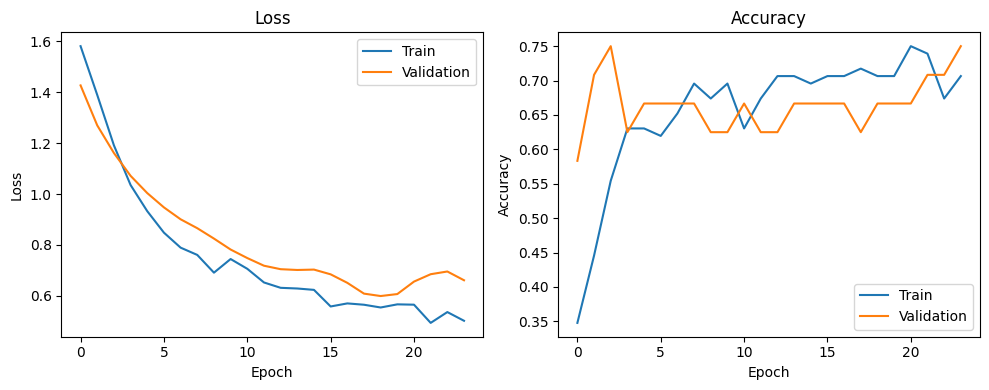

In [ ]:
print("---Training the ANN---")
ann = ANN(
    X_train, X_test, y_train, y_test,
    num_classes
    )
history = ann.fit_ann("relu", "Adam", 0.3)
ann.eval()
ann.plot_val(history)

In [ ]:
ann.cross_val("relu", "Adam", 0.3)

Fold 1
Activation: relu
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5417 - loss: 1.3437
Validation Accuracy: 0.5417
--------------------------------------------------
Fold 2
Activation: relu
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5652 - loss: 1.4292
Validation Accuracy: 0.5652
--------------------------------------------------
Fold 3
Activation: relu
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6087 - loss: 1.3256
Validation Accuracy: 0.6087
--------------------------------------------------
Fold 4
Activation: relu
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.4348 - loss: 1.5213
Validation Accuracy: 0.4348
--------------------------------------------------
Fold 5
Activation: relu
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.5217 - loss: 1.4480
Validation Accuracy: 0.5217
--------------------------------------------------
Mean Acc:0.5344


np.float64(0.5344202816486359)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       0.83      0.45      0.59        11
           2       0.67      1.00      0.80         4
           3       0.43      0.50      0.46         6
           4       0.62      0.83      0.71         6

    accuracy                           0.66        29
   macro avg       0.71      0.76      0.71        29
weighted avg       0.69      0.66      0.65        29



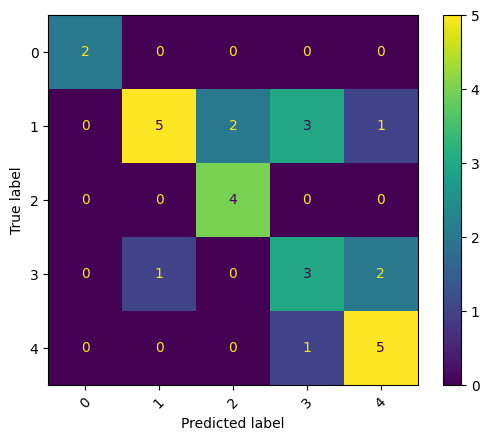

In [ ]:
ann.diagnostic_report()

In [ ]:
unmatched_scaled = scaler.transform(
    unmatched_df[pitch_cols]
)

In [ ]:
pred_probs = ann.model.predict(unmatched_scaled)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step 


In [ ]:
pred_idx = np.argmax(
    pred_probs,
    axis=1
)

In [ ]:
pred_labels = label_enc.inverse_transform(
    pred_idx
)

In [ ]:
confidence = pred_probs.max(axis=1)

In [ ]:
unmatched_df['PredictedPitchType'] = pred_labels

unmatched_df['PredictionConfidence'] = confidence

In [ ]:
threshold = 0.75
unmatched_df['FinalPitchType'] = np.where(
    unmatched_df['PredictionConfidence'] >= threshold,
    unmatched_df['PredictedPitchType'],
    'UNMATCHED'
)

In [ ]:
df.loc[
    unmatched_df.index,
    'TaggedPitchType'
] = unmatched_df['FinalPitchType']

In [ ]:
unmatched_df[
    ['PredictedPitchType',
     'PredictionConfidence']
].head(20)

,PredictedPitchType,PredictionConfidence
15,Fast,0.655019
16,Fast,0.829520
18,Fast,0.600767
20,Curve,0.544261
21,Fast,0.970601
23,Curve,0.566371
24,Fast,0.644618
26,Fast,0.915585
27,Fast,0.854547
28,Fast,0.958315


In [ ]:
unmatched_df['PredictedPitchType'].value_counts()

,count
PredictedPitchType,
Fast,48
Curve,24
Screw,9
Change,6
Rise,4


#### So now we have a small amount of missing rows for 'TaggedPitchType'.

#### Additionally, for the numerical features that we want to use for modeling, only a small percentage are missing and could be safe enough to drop.

### Next we can use PCA to find the most important numerical features


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_df = imputed_df[pitch_cols].dropna().copy() # Use pitch cols, this will be like a mask/grouping
scaler=StandardScaler()
X_scaled=scaler.fit_transform(pca_df)

pca=PCA(n_components=len(pitch_cols))
X_pca=pca.fit_transform(X_scaled)

In [ ]:
print_shape(pca_df)

In [ ]:
print_missing(pca_df)

#### We want to dramatically reduce the dimensions

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract the variance data from your PCA object
exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
num_components = len(exp_var)

# 2. Set up a dual-axis plot structure for clarity
fig, ax1 = plt.subplots(figsize=(12, 6))

# Ax1: Individual variance per component (Bar chart)
bars = ax1.bar(
    range(1, num_components + 1),
    exp_var,
    alpha=0.6,
    color='steelblue',
    label='Individual Variance'
)
ax1.set_xlabel('Principal Component Index')
ax1.set_ylabel('Individual Explained Variance Ratio', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xticks(range(1, num_components + 1, 2))  # Cleaner ticks for 29 points

# Ax2: Cumulative variance tracking (Line chart on twin axis)
ax2 = ax1.twinx()
line = ax2.plot(
    range(1, num_components + 1),
    cum_var,
    marker='o',
    color='darkorange',
    linewidth=2,
    label='Cumulative Variance'
)
ax2.set_ylabel('Cumulative Explained Variance Ratio', color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')

# 3. Add an 85% benchmark horizontal line to identify the "Elbow"
ax2.axhline(y=0.9, color='red', linestyle='--', alpha=0.7, label='90% Threshold Line')

# 4. Final layout dressing
plt.title('PCA Scree Plot: Determining Optimal Top N Components', fontsize=14, pad=15)
ax1.grid(True, axis='x', linestyle=':', alpha=0.6)

# Combine labels from both axes into a single clean legend box
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.tight_layout()
plt.show()


In [ ]:
# we keep 5 PCAs
PCA_list=['StrengthThrow', 'EndDirection', 'StrengthSpin', 'Trajectory', 'InitialDirection']
loadings = pd.DataFrame(
    pca.components_[:5].T,
    columns=[col for col in PCA_list],
    index=pitch_cols
)


# 2. Plot the Heatmap
plt.figure(figsize=(10, 8))

# Using a diverging color palette (coolwarm) so negative/positive weights are obvious
sns.heatmap(
    loadings,
    annot=True,          # Displays the weight values inside the cells
    fmt=".2f",          # Rounds weights to two decimal places
    cmap="coolwarm",    # Red = strongly positive, Blue = strongly negative
    vmin=-1, vmax=1,    # Forces scale boundary to match correlation limits
    linewidths=0.5
)

plt.title("PCA Loadings Heatmap (Top 5 Components)", fontsize=14, pad=15)
plt.ylabel("Original Pitch Features")
plt.xlabel("Principal Components")
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15,10))

for i, pc in enumerate(PCA_list):

    loadings[pc].sort_values().plot.barh(
        ax=ax.flat[i]
    )

    ax.flat[i].set_title(f'{pc}')
    ax.flat[i].axvline(0, color='black')
    ax.flat[i].tick_params(axis='x', rotation=45)
    ax.flat[i].set_xlim(-.4,.4)

plt.tight_layout()
plt.suptitle("Feature Importance")
plt.show()

Testing the model with PCA

In [ ]:
from sklearn.cluster import KMeans

# reuse pca_df, X_scaled.

pca = PCA(n_components=5)
pca_scores = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_scores,
    columns=[col for col in PCA_list],
    index=pca_df.index
)


# concating the nominal cols from the original df
nom_cols = ['Pitcher', 'PitcherTeam', 'TaggedPitchType']
player_team_pca_df = pd.concat(
    [pca_df, imputed_df[pitch_cols+nom_cols]],
    axis=1
)


In [ ]:
print_shape(player_team_pca_df)

In [ ]:
player_team_pca_df = player_team_pca_df[
    (player_team_pca_df['TaggedPitchType'] != 'UNMATCHED')
      ].dropna().copy() # we drop a little bit of the data
print_shape(player_team_pca_df)

### Making predictions based on Player

In [ ]:
# using umap
import umap
import plotly.express as px

X = player_team_pca_df[PCA_list]

In [ ]:
reducer = umap.UMAP(n_neighbors=10, random_state=42, min_dist=0.1)
embedding = reducer.fit_transform(X)
player_team_pca_df['UMAP1'], player_team_pca_df['UMAP2'] = embedding[:,0], embedding[:,1]

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(nom_cols):

    sns.scatterplot(
        data=player_team_pca_df,
        x='UMAP1',
        y='UMAP2',
        hue=col,
        ax=ax[i],
        alpha=0.7,
        s=30
    )

    ax[i].set_title(f'UMAP by {col}')

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Masks
UTA=player_team_pca_df[player_team_pca_df['PitcherTeam']=='Uta fall 25']
SD=player_team_pca_df[player_team_pca_df['PitcherTeam']=='South dakota state [sou03:2025]']
sns.scatterplot(
    data=SD,
    x='UMAP1',
    y='UMAP2',
    hue='TaggedPitchType',
    style='Pitcher',
    ax=ax[0]
).set_title('South Dakota State')
sns.scatterplot(
    data=UTA,
    x='UMAP1',
    y='UMAP2',
    hue='TaggedPitchType',
    style='Pitcher',
    ax=ax[1]
).set_title('UTA')

plt.tight_layout()
plt.show()

In [ ]:
# using hdbscan
import hdbscan
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=10,
)
clusters = clusterer.fit_predict(X)

player_team_pca_df['HDBSCAN_Cluster'] = clusters

In [ ]:
reducer = umap.UMAP(
    n_neighbors=10,
    min_dist=0.1,
    random_state=42
)

X_umap = reducer.fit_transform(X)

In [ ]:
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=15,
    min_samples=10
)

clusters = clusterer.fit_predict(X_umap)

player_team_pca_df['UMAP_HDBSCAN'] = clusters

In [ ]:
plt.figure(figsize=(10,8))

sns.scatterplot(
    x=X_umap[:,0],
    y=X_umap[:,1],
    hue=clusters,
    palette='tab20'
)

plt.title('UMAP + HDBSCAN')
plt.show()

In [ ]:
pitcher_pitchtype = pd.crosstab(
    player_team_pca_df['Pitcher'],
    player_team_pca_df['TaggedPitchType'],
    normalize='index'
)

pitcher_pitchtype.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.ylabel('Proportion')
plt.title('Pitch Type Distribution by Pitcher')
plt.show()

#### More descriptive plots

In [ ]:
UTA=player_team_pca_df[player_team_pca_df['PitcherTeam']=='Uta fall 25']
SD=player_team_pca_df[player_team_pca_df['PitcherTeam']=='South dakota state [sou03:2025]']

In [ ]:
UTA_Pitchers = UTA['Pitcher'].unique()
UTA_Pitchers

In [ ]:
SD_Pitchers = SD['Pitcher'].unique()
SD_Pitchers

#### We get a plot for avg speed per pitch type

In [ ]:
pitcher = 'Maddie Furniss'
arsenal = (
    player_team_pca_df
    .query('Pitcher == @pitcher')
    .groupby('TaggedPitchType')
    .agg(
        Count=('TaggedPitchType', 'size'),
        AvgSpeed=('RelSpeed', 'mean')
    )
)

arsenal['Frequency'] = (
    arsenal['Count']
    / arsenal['Count'].sum()
)

arsenal = arsenal.sort_values(
    'Frequency',
    ascending=False
)
############################################ plotting
fig, ax = plt.subplots(
    1, 2,
    figsize=(12, 5),
    gridspec_kw={'width_ratios':[1,2]}
)

# Frequency bars
ax[0].barh(
    arsenal.index,
    arsenal['Frequency']*100
)

ax[0].set_title('Pitch Frequency')
ax[0].set_xlabel('Percent')

# Average velocity dots
ax[1].scatter(
    arsenal['AvgSpeed'],
    arsenal.index,
    s=200
)

for i, speed in enumerate(arsenal['AvgSpeed']):
    ax[1].text(
        speed + 0.01,
        i,
        f'{speed:.1f}'
    )

ax[1].set_title('Average RelSpeed')
ax[1].set_xlabel('MPH')

plt.suptitle(f"{pitcher}'s Pitch Types")
plt.tight_layout()
plt.show()


In [ ]:
zone_df = (
    player_team_pca_df
    .query("Pitcher == 'Maddie Furniss'")
    [['PlateLocSide', 'PlateLocHeight']]
    .dropna()
)

zone_df['x_bin'] = pd.cut(
    zone_df['PlateLocSide'],
    bins=3,
    labels=[1,2,3]
)

zone_df['y_bin'] = pd.cut(
    zone_df['PlateLocHeight'],
    bins=3,
    labels=[3,2,1]
)

strike_zone = pd.crosstab(
    zone_df['y_bin'],
    zone_df['x_bin']
)

plt.figure(figsize=(6,6))

sns.heatmap(
    strike_zone,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    cbar=False
)

plt.title("Maddie Furniss's Pitch Location Frequency")
plt.xlabel('')
plt.ylabel('')

plt.show()

In [ ]:
pitch = (
    player_team_pca_df
    .query(
        "Pitcher == 'Maddie Furniss' and TaggedPitchType == 'Curve'"
    )
    [['PlateLocSide', 'PlateLocHeight']]
    .dropna()
)

zone_df = pitch[
    ['PlateLocSide', 'PlateLocHeight']
].dropna()

zone_df['x_bin'] = pd.cut(
    zone_df['PlateLocSide'],
    bins=3,
    labels=[1,2,3]
)

zone_df['y_bin'] = pd.cut(
    zone_df['PlateLocHeight'],
    bins=3,
    labels=[3,2,1]
)

strike_zone = pd.crosstab(
    zone_df['y_bin'],
    zone_df['x_bin']
)

plt.figure(figsize=(6,6))

sns.heatmap(
    strike_zone,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    cbar=False
)

plt.title("Maddie Furniss's Curve Ball Location Frequency")
plt.xlabel('')
plt.ylabel('')

plt.show()

In [ ]:
print_unique(player_team_pca_df, 'Pitcher')

In [ ]:
plt.figure(figsize=(10,10))
player = (
    player_team_pca_df
    .query(
        "Pitcher == 'Maddie Furniss'"
    )
    .dropna()
)
sns.scatterplot(
    data=player,
    x='PlateLocSide',
    y='PlateLocHeight',
    hue='TaggedPitchType',
    alpha=0.9,
    s=300
)

# strike zone
zone_left = -0.83
zone_right = 0.83
zone_bottom = 1.5
zone_top = 3.5

plt.plot(
    [zone_left, zone_right, zone_right, zone_left, zone_left],
    [zone_bottom, zone_bottom, zone_top, zone_top, zone_bottom],
    color='black'
)
plt.xlim(-3, 3)
plt.ylim(0, 5)

plt.title("Maddie Furniss's Pitch Locations")
plt.show()

In [ ]:
# Strike zone
zone_left = -0.83
zone_right = 0.83
zone_bottom = 1.5
zone_top = 3.5

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
pitchers = (
    player_team_pca_df['Pitcher']
    .dropna()
    .unique()
)
for i, pitcher in enumerate(pitchers):

    subset = player_team_pca_df[
        (player_team_pca_df['Pitcher'] == pitcher)
        &
        (player_team_pca_df['TaggedPitchType'] == 'Curve')
    ]

    current_ax = ax.flat[i]

    sns.scatterplot(
        data=subset,
        x='PlateLocSide',
        y='PlateLocHeight',
        #fill=True,
        #cmap='Reds',
        ax=current_ax,
        #levels=10,
        hue='TaggedPitchType',
        alpha=0.9,
        s=200
    )

    # Draw strike zone
    current_ax.plot(
        [zone_left, zone_right, zone_right, zone_left, zone_left],
        [zone_bottom, zone_bottom, zone_top, zone_top, zone_bottom],
        color='black'
    )

    current_ax.set_title(pitcher)
    current_ax.set_aspect('equal')
    current_ax.set_xlim(-3, 3)
    current_ax.set_ylim(0, 5)

# Hide unused subplot(s)
for j in range(i + 1, len(ax.flat)):
    ax.flat[j].set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:
# Strike zone
zone_left = -0.83
zone_right = 0.83
zone_bottom = 1.5
zone_top = 3.5

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
pitchers = (
    player_team_pca_df['Pitcher']
    .dropna()
    .unique()
)
for i, pitcher in enumerate(pitchers):

    subset = player_team_pca_df[
        (player_team_pca_df['Pitcher'] == pitcher)
        &
        (player_team_pca_df['TaggedPitchType'] == 'Curve')
    ]

    current_ax = ax.flat[i]

    sns.kdeplot(
        data=subset,
        x='PlateLocSide',
        y='PlateLocHeight',
        fill=True,
        cmap='Reds',
        ax=current_ax,
        levels=10
    )

    # Draw strike zone
    current_ax.plot(
        [zone_left, zone_right, zone_right, zone_left, zone_left],
        [zone_bottom, zone_bottom, zone_top, zone_top, zone_bottom],
        color='black'
    )

    current_ax.set_title(pitcher)
    current_ax.set_aspect('equal')
    current_ax.set_xlim(-3, 3)
    current_ax.set_ylim(0, 5)

# Hide unused subplot(s)
for j in range(i + 1, len(ax.flat)):
    ax.flat[j].set_visible(False)

plt.tight_layout()
plt.show()
